# Laboratório - Dataset Titanic
**EDA, Tratamento e Limpeza, Feature Engineering**

Estrutura:
1. Análise Exploratória de Dados (EDA)
2. Tratamento e Limpeza
3. Feature Engineering

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

df_raw = sns.load_dataset('titanic')

# visualização inicial
print(f"Dimensões do DataFrame: {df_raw.shape}")
df_raw.head()

Dimensões do DataFrame: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.00,1,0,7.25,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.00,1,0,71.28,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.00,0,0,7.92,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.00,1,0,53.10,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.00,0,0,8.05,S,Third,man,True,NaN,Southampton,no,True


## 1. Análise Exploratória de Dados (EDA)
### 1.1 Estrutura dos dados

In [2]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [3]:
estrutura = pd.DataFrame({
    'tipo': df_raw.dtypes.astype(str),
    'nulos': df_raw.isna().sum(),
    '%_nulos': (df_raw.isna().mean() * 100).round(1),
    'valores_únicos': df_raw.nunique(),
})
estrutura

,tipo,nulos,%_nulos,valores_únicos
survived,int64,0,0.00,2
pclass,int64,0,0.00,3
sex,object,0,0.00,2
age,float64,177,19.90,88
sibsp,int64,0,0.00,7
parch,int64,0,0.00,7
fare,float64,0,0.00,248
embarked,object,2,0.20,3
class,category,0,0.00,3
who,object,0,0.00,3


**Leitura da estrutura:**
- Numéricas contínuas: `age`, `fare`. Numéricas discretas (contagens): `sibsp`, `parch`.
- Alvo: `survived` (0 = morreu, 1 = sobreviveu).
- Categóricas: `pclass`/`class`, `sex`, `embarked`/`embark_town`, `who`, `deck`.
- Várias colunas são **derivadas de outras** (`class`, `alive`, `embark_town`, `adult_male`, `alone`), o que será tratado na limpeza.
- Valores ausentes concentrados em `deck`, `age` e, em menor grau, `embarked`/`embark_town`.

### 1.2 Medidas descritivas

In [4]:
num_cols = ['age', 'fare', 'sibsp', 'parch']

desc = df_raw[num_cols].agg(['count', 'mean', 'median', 'std', 'min', 'max']).T
desc['Q1'] = df_raw[num_cols].quantile(0.25)
desc['Q3'] = df_raw[num_cols].quantile(0.75)
desc['AIQ'] = desc['Q3'] - desc['Q1']                 # amplitude interquartil
desc['CV'] = desc['std'] / desc['mean']               # coeficiente de variação
desc['assimetria'] = df_raw[num_cols].skew()
desc

,count,mean,median,std,min,max,Q1,Q3,AIQ,CV,assimetria
age,714.00,29.70,28.00,14.53,0.42,80.00,20.12,38.00,17.88,0.49,0.39
fare,891.00,32.20,14.45,49.69,0.00,512.33,7.91,31.00,23.09,1.54,4.79
sibsp,891.00,0.52,0.00,1.10,0.00,8.00,0.00,1.00,1.00,2.11,3.70
parch,891.00,0.38,0.00,0.81,0.00,6.00,0.00,0.00,0.00,2.11,2.75


`fare` tem média (~32) bem acima da mediana (~14) e assimetria alta: a distribuição tem cauda longa à direita, com poucas tarifas muito altas. Por isso a mediana e a escala logarítmica descrevem melhor essa variável do que a média. `sibsp` e `parch` são concentradas em 0.

In [7]:
# distribuição das variáveis categóricas
for col in ['survived', 'pclass', 'sex', 'embarked', 'who']:
    cont = df_raw[col].value_counts(dropna=False)
    tabela = pd.DataFrame({'n': cont, '%': (cont / len(df_raw) * 100).round(1)})
    print(f'--- {col} ---')
    print(tabela.to_string(), '\n')

print(f"Taxa de sobrevivência global: {df_raw['survived'].mean():.1%}")

--- survived ---
            n     %
survived           
0         549 61.60
1         342 38.40 

--- pclass ---
          n     %
pclass           
3       491 55.10
1       216 24.20
2       184 20.70 

--- sex ---
          n     %
sex              
male    577 64.80
female  314 35.20 

--- embarked ---
            n     %
embarked           
S         644 72.30
C         168 18.90
Q          77  8.60
NaN         2  0.20 

--- who ---
         n     %
who             
man    537 60.30
woman  271 30.40
child   83  9.30 

Taxa de sobrevivência global: 38.4%


In [8]:
# taxa de sobrevivência por grupo
linhas = []
for col in ['sex', 'pclass', 'embarked', 'who']:
    g = df_raw.groupby(col)['survived'].agg(['mean', 'count'])
    g.index = [f'{col} = {i}' for i in g.index]
    linhas.append(g)

taxas = pd.concat(linhas).rename(columns={'mean': 'taxa_sobrevivência', 'count': 'n'})
taxas

,taxa_sobrevivência,n
sex = female,0.74,314
sex = male,0.19,577
pclass = 1,0.63,216
pclass = 2,0.47,184
pclass = 3,0.24,491
embarked = C,0.55,168
embarked = Q,0.39,77
embarked = S,0.34,644
who = child,0.59,83
who = man,0.16,537


### 1.3 Gráficos: distribuições e padrões de sobrevivência

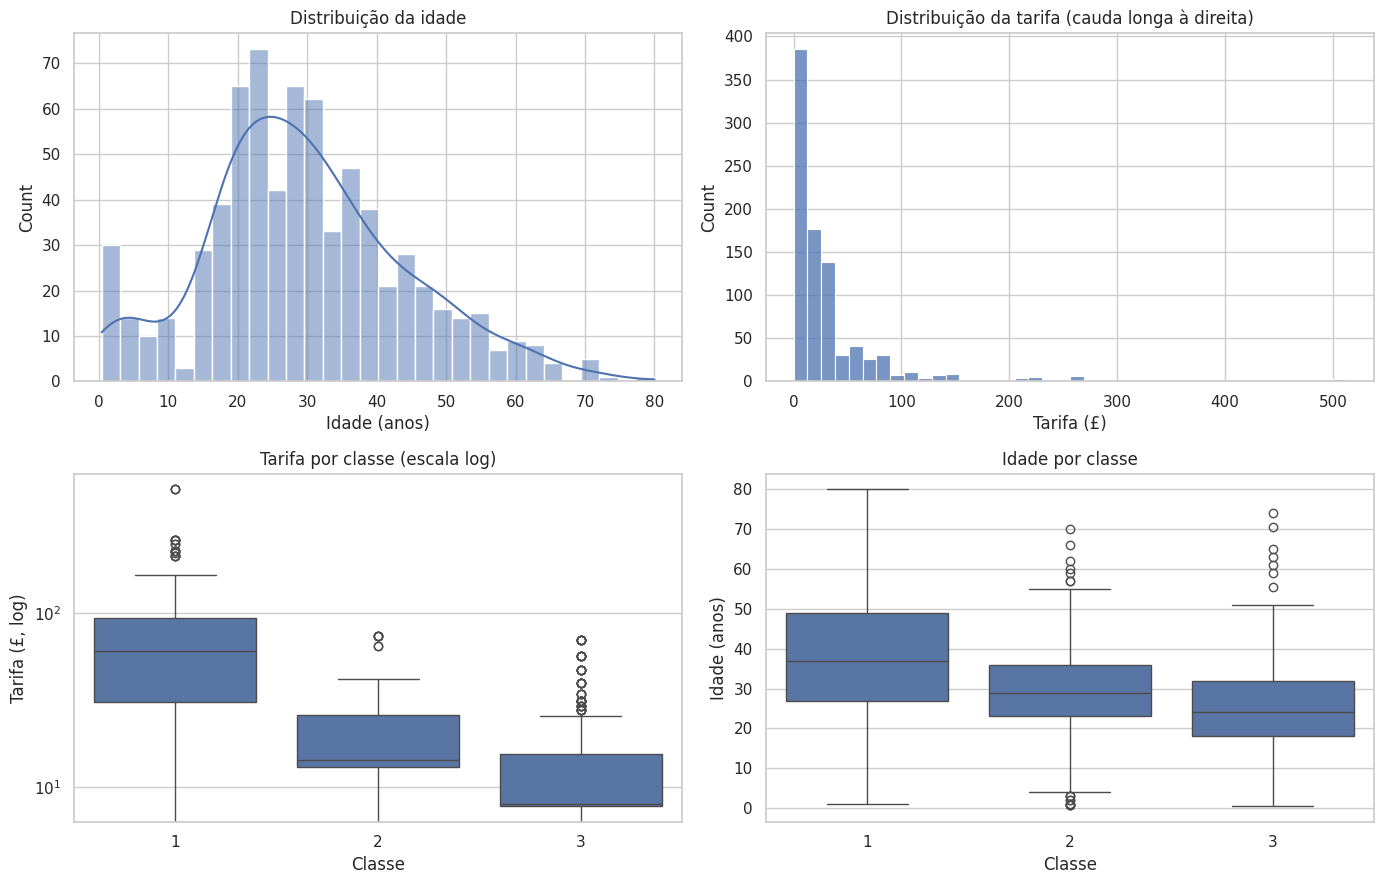

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(df_raw['age'].dropna(), bins=30, kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Distribuição da idade')
axes[0, 0].set_xlabel('Idade (anos)')

sns.histplot(df_raw['fare'], bins=40, ax=axes[0, 1])
axes[0, 1].set_title('Distribuição da tarifa (cauda longa à direita)')
axes[0, 1].set_xlabel('Tarifa (£)')

sns.boxplot(data=df_raw, x='pclass', y='fare', ax=axes[1, 0])
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('Tarifa por classe (escala log)')
axes[1, 0].set_xlabel('Classe')
axes[1, 0].set_ylabel('Tarifa (£, log)')

sns.boxplot(data=df_raw, x='pclass', y='age', ax=axes[1, 1])
axes[1, 1].set_title('Idade por classe')
axes[1, 1].set_xlabel('Classe')
axes[1, 1].set_ylabel('Idade (anos)')

plt.tight_layout()
plt.show()

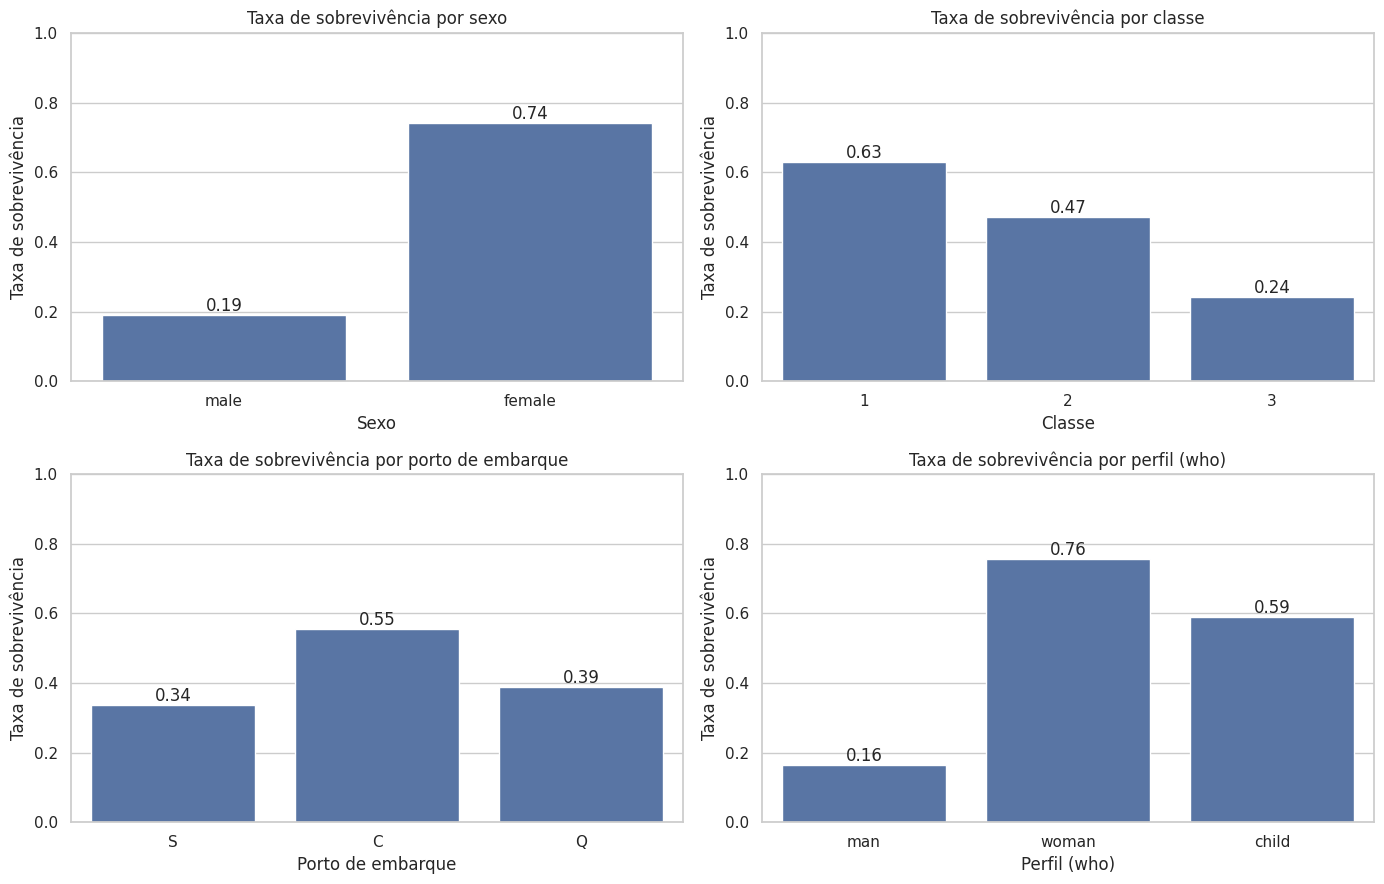

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (col, titulo) in zip(axes.ravel(), [('sex', 'Sexo'), ('pclass', 'Classe'),
                                            ('embarked', 'Porto de embarque'), ('who', 'Perfil (who)')]):
    sns.barplot(data=df_raw, x=col, y='survived', errorbar=None, ax=ax)
    ax.bar_label(ax.containers[0], fmt='%.2f')
    ax.set_title(f'Taxa de sobrevivência por {titulo.lower()}')
    ax.set_xlabel(titulo)
    ax.set_ylabel('Taxa de sobrevivência')
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

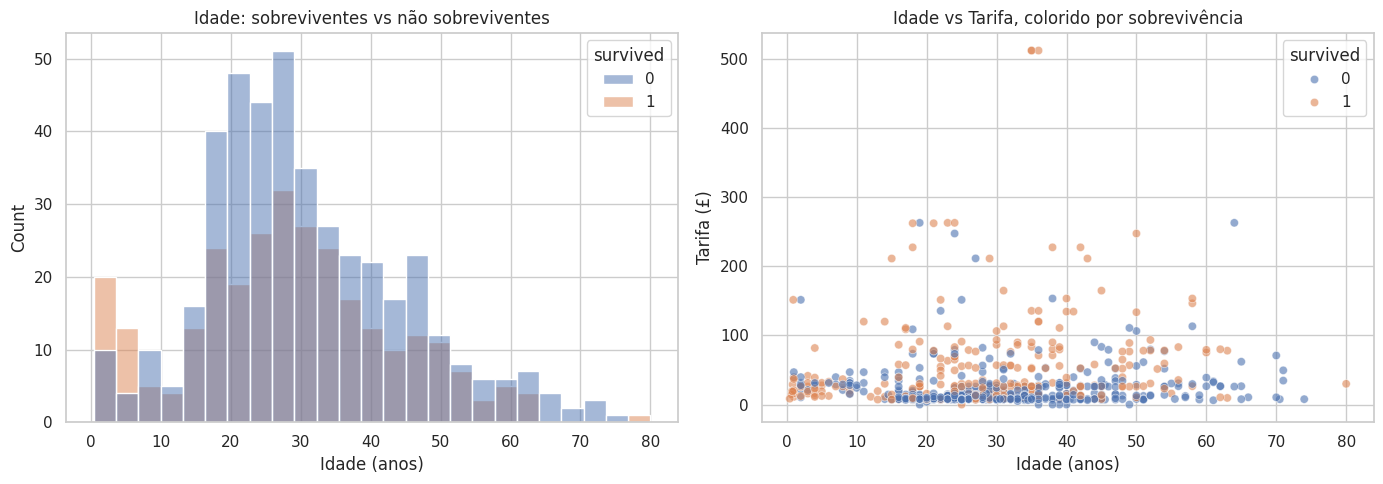

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_raw.dropna(subset=['age']), x='age', hue='survived', bins=25,
             multiple='layer', alpha=0.5, ax=axes[0])
axes[0].set_title('Idade: sobreviventes vs não sobreviventes')
axes[0].set_xlabel('Idade (anos)')

sns.scatterplot(data=df_raw, x='age', y='fare', hue='survived', alpha=0.6, ax=axes[1])
axes[1].set_title('Idade vs Tarifa, colorido por sobrevivência')
axes[1].set_xlabel('Idade (anos)')
axes[1].set_ylabel('Tarifa (£)')

plt.tight_layout()
plt.show()

### 1.4 Correlações e padrões cruzados

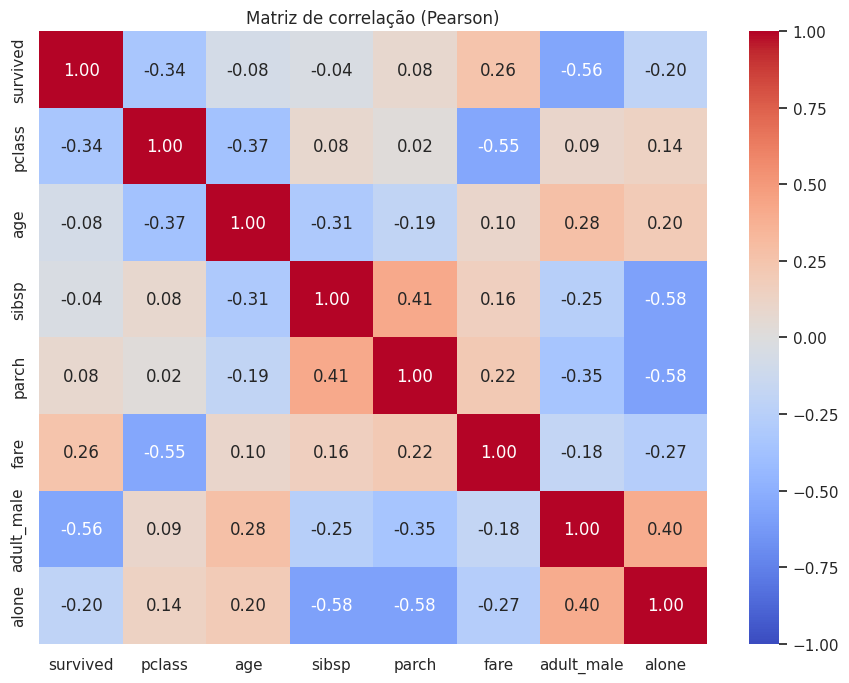

Correlação com a sobrevivência:
adult_male   -0.56
pclass       -0.34
alone        -0.20
age          -0.08
sibsp        -0.04
parch         0.08
fare          0.26


In [12]:
cols_corr = ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'adult_male', 'alone']
corr = df_raw[cols_corr].astype(float).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlação (Pearson)')
plt.tight_layout()
plt.show()

print('Correlação com a sobrevivência:')
print(corr['survived'].drop('survived').sort_values().to_string())

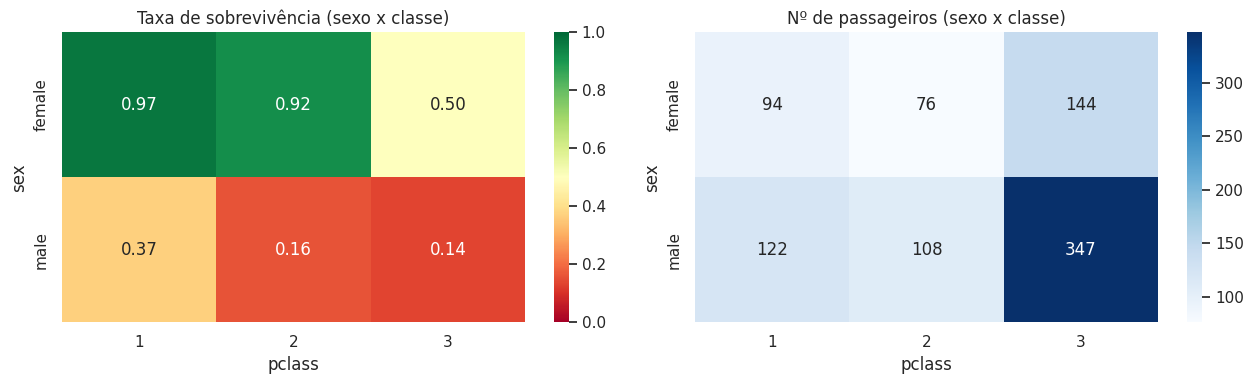

In [13]:
# sexo x classe: o cruzamento revela mais do que cada variável sozinha
taxa_sc = df_raw.pivot_table(index='sex', columns='pclass', values='survived', aggfunc='mean')
n_sc = df_raw.pivot_table(index='sex', columns='pclass', values='survived', aggfunc='count')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(taxa_sc, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1, ax=axes[0])
axes[0].set_title('Taxa de sobrevivência (sexo x classe)')
sns.heatmap(n_sc, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Nº de passageiros (sexo x classe)')
plt.tight_layout()
plt.show()

**Principais padrões da EDA:**
- **Sexo** é o fator mais forte: mulheres sobreviveram muito mais que homens.
- **Classe** também pesa: a taxa cai da 1ª para a 3ª classe, e `pclass` tem correlação negativa com a sobrevivência.
- O cruzamento mostra que mulheres de 1ª e 2ª classe tiveram taxas altíssimas, enquanto homens de 2ª e 3ª classe tiveram taxas baixas.
- Crianças (`who = child`) tiveram taxa maior que homens adultos.
- `fare` está correlacionada positivamente com a sobrevivência, em grande parte porque é um reflexo da classe.

## 2. Tratamento e Limpeza
### 2.1 Valores em falta

,n_nulos,%_nulos
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


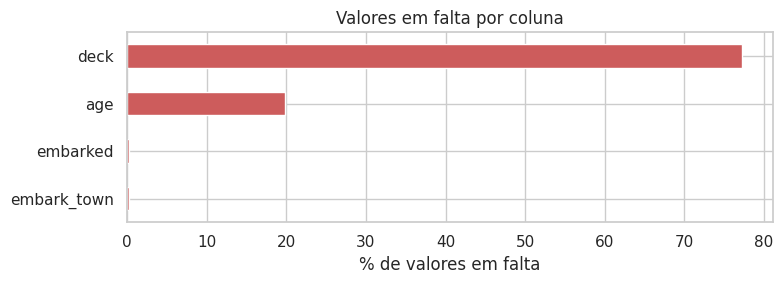

In [14]:
faltantes = pd.DataFrame({
    'n_nulos': df_raw.isna().sum(),
    '%_nulos': (df_raw.isna().mean() * 100).round(2),
})
faltantes = faltantes[faltantes['n_nulos'] > 0].sort_values('n_nulos', ascending=False)
display(faltantes)

fig, ax = plt.subplots(figsize=(8, 3))
faltantes['%_nulos'].plot(kind='barh', ax=ax, color='indianred')
ax.set_xlabel('% de valores em falta')
ax.set_title('Valores em falta por coluna')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 2.2 Registros redundantes e inconsistências

O dataset **não tem identificador de passageiro**. Assim, dois registros idênticos em todas as colunas não podem ser confirmados como o mesmo passageiro (podem ser, por exemplo, duas pessoas da mesma família, com o mesmo bilhete e perfil). Mesmo assim, o enunciado pede o tratamento de registros redundantes, então eles são identificados aqui e a remoção fica controlada por uma variável (`REMOVER_DUPLICADOS`), para que seja possível comparar o efeito.

In [15]:
mascara_dup = df_raw.duplicated(keep=False)
print(f'Registros envolvidos em duplicação (todas as cópias): {mascara_dup.sum()}')
print(f'Cópias redundantes (excluindo a 1ª ocorrência): {df_raw.duplicated().sum()}')
print(f"Taxa de sobrevivência nos registros duplicados: {df_raw.loc[mascara_dup, 'survived'].mean():.1%}")
print(f"Taxa de sobrevivência nos demais registros:     {df_raw.loc[~mascara_dup, 'survived'].mean():.1%}")

Registros envolvidos em duplicação (todas as cópias): 160
Cópias redundantes (excluindo a 1ª ocorrência): 107
Taxa de sobrevivência nos registros duplicados: 19.4%
Taxa de sobrevivência nos demais registros:     42.5%


In [16]:
# checagens de consistência lógica entre colunas
mapa_classe = {'First': 1, 'Second': 2, 'Third': 3}
mapa_porto = {'C': 'Cherbourg', 'Q': 'Queenstown', 'S': 'Southampton'}

checagens = {
    'alone diferente de (sibsp + parch == 0)':
        (df_raw['alone'] != ((df_raw['sibsp'] + df_raw['parch']) == 0)).sum(),
    'alive diferente de survived':
        ((df_raw['alive'] == 'yes').astype(int) != df_raw['survived']).sum(),
    'class diferente de pclass':
        (df_raw['class'].astype(str).map(mapa_classe) != df_raw['pclass']).sum(),
    'embarked diferente de embark_town':
        ((df_raw['embarked'].map(mapa_porto) != df_raw['embark_town']) & df_raw['embarked'].notna()).sum(),
    'adult_male diferente de (who == man)':
        ((df_raw['who'] == 'man') != df_raw['adult_male']).sum(),
    'who = child com idade >= 16':
        ((df_raw['who'] == 'child') & (df_raw['age'] >= 16)).sum(),
    'idade fora de 0-100':
        ((df_raw['age'] < 0) | (df_raw['age'] > 100)).sum(),
    'tarifa = 0 (bilhetes de cortesia/tripulação, mantidos)':
        (df_raw['fare'] == 0).sum(),
}
pd.Series(checagens, name='nº de casos').astype(int).to_frame()

,nº de casos
alone diferente de (sibsp + parch == 0),0
alive diferente de survived,0
class diferente de pclass,0
embarked diferente de embark_town,0
adult_male diferente de (who == man),0
who = child com idade >= 16,0
idade fora de 0-100,0
"tarifa = 0 (bilhetes de cortesia/tripulação, mantidos)",15


In [17]:
# outliers pelo critério do IQR (apenas diagnóstico)
for col in ['age', 'fare']:
    q1, q3 = df_raw[col].quantile([0.25, 0.75])
    lim_inf, lim_sup = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n_out = ((df_raw[col] < lim_inf) | (df_raw[col] > lim_sup)).sum()
    print(f'{col}: limites [{lim_inf:.1f}, {lim_sup:.1f}] -> {n_out} valores fora ({n_out / df_raw[col].notna().sum():.1%})')

age: limites [-6.7, 64.8] -> 11 valores fora (1.5%)
fare: limites [-26.7, 65.6] -> 116 valores fora (13.0%)


**Diagnóstico:** não há inconsistências lógicas entre as colunas derivadas. As tarifas altas aparecem como outliers estatísticos, mas são valores reais (1ª classe, cabines de luxo), então **não serão removidas**: serão tratadas com transformação logarítmica na etapa de feature engineering.

### 2.3 Ações de limpeza

| Problema | Decisão | Justificativa |
|---|---|---|
| Registros duplicados | Remover cópias redundantes (mantém a 1ª) | Pedido no enunciado; ver ressalva sobre ausência de ID |
| `age` com ~20% de nulos | Imputar pela **mediana de sexo x classe** e criar a flag `idade_imputada` | A idade varia por classe e sexo; a flag preserva a informação de que o valor foi estimado |
| `embarked` com 2 nulos | Imputar pela **moda** | Poucos casos, categoria dominante |
| `deck` com ~77% de nulos | **Remover coluna** | Imputar geraria mais ruído que informação |
| `class`, `alive`, `embark_town`, `adult_male`, `alone` | **Remover** | São cópias/derivações de `pclass`, `survived`, `embarked`, `who`/`sex`/`age`, `sibsp`/`parch` |
| Tarifa = 0 e tarifas altas | **Manter** | Valores plausíveis |

In [18]:
REMOVER_DUPLICADOS = True

df = df_raw.copy()
log = []

# 1. duplicados
n_antes = len(df)
if REMOVER_DUPLICADOS:
    df = df.drop_duplicates().reset_index(drop=True)
log.append(('registros', 'Remoção de cópias redundantes', n_antes - len(df)))

# 2. idade: flag + mediana por sexo x classe
df['idade_imputada'] = df['age'].isna().astype(int)
n_age = int(df['age'].isna().sum())
mediana_grupo = df.groupby(['sex', 'pclass'])['age'].transform('median')
df['age'] = df['age'].fillna(mediana_grupo)
log.append(('age', 'Imputação pela mediana de sexo x classe (+ flag idade_imputada)', n_age))

# 3. porto de embarque: moda
n_emb = int(df['embarked'].isna().sum())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
log.append(('embarked', 'Imputação pela moda', n_emb))

# 4. deck: removido
n_deck = int(df['deck'].isna().sum())
df = df.drop(columns='deck')
log.append(('deck', 'Coluna removida (muitos nulos)', n_deck))

# 5. colunas redundantes
for col, motivo in [('class', 'duplica pclass'), ('alive', 'duplica survived'),
                    ('embark_town', 'duplica embarked'), ('adult_male', 'derivada de who'),
                    ('alone', 'derivada de sibsp + parch')]:
    df = df.drop(columns=col)
    log.append((col, f'Coluna removida ({motivo})', 0))

resumo_acoes = pd.DataFrame(log, columns=['alvo', 'ação', 'registros/valores afetados'])
resumo_acoes

,alvo,ação,registros/valores afetados
0,registros,Remoção de cópias redundantes,107
1,age,Imputação pela mediana de sexo x classe (+ fla...,106
2,embarked,Imputação pela moda,2
3,deck,Coluna removida (muitos nulos),582
4,class,Coluna removida (duplica pclass),0
5,alive,Coluna removida (duplica survived),0
6,embark_town,Coluna removida (duplica embarked),0
7,adult_male,Coluna removida (derivada de who),0
8,alone,Coluna removida (derivada de sibsp + parch),0


### 2.4 Resumo antes x depois

In [19]:
comparativo = pd.DataFrame({
    'antes': [df_raw.shape[0], df_raw.shape[1], int(df_raw.isna().sum().sum()),
              df_raw['survived'].mean(), df_raw['age'].median(), df_raw['age'].mean()],
    'depois': [df.shape[0], df.shape[1], int(df.isna().sum().sum()),
               df['survived'].mean(), df['age'].median(), df['age'].mean()],
}, index=['linhas', 'colunas', 'valores em falta', 'taxa de sobrevivência', 'idade mediana', 'idade média'])
comparativo

,antes,depois
linhas,891.00,784.00
colunas,15.00,10.00
valores em falta,869.00,0.00
taxa de sobrevivência,0.38,0.41
idade mediana,28.00,28.00
idade média,29.70,29.64


In [20]:
# a limpeza preservou o padrão sexo x classe?
df.pivot_table(index='sex', columns='pclass', values='survived', aggfunc='mean')

pclass,1,2,3
sex,,,
female,0.97,0.92,0.47
male,0.37,0.18,0.16


## 3. Feature Engineering
### 3.1 Agregação de laços familiares

- `tamanho_familia` = `sibsp` + `parch` + 1 (o próprio passageiro)
- `viaja_sozinho` (binária)
- `grupo_familia` (Sozinho, Pequena 2-4, Grande 5+)
- `tarifa_por_pessoa` (corrige o efeito de bilhetes compartilhados)
- `fare_log` = log(1 + `fare`) (reduz a assimetria)

In [21]:
fe = df.copy()

fe['tamanho_familia'] = fe['sibsp'] + fe['parch'] + 1
fe['viaja_sozinho'] = (fe['tamanho_familia'] == 1).astype(int)
fe['grupo_familia'] = pd.cut(fe['tamanho_familia'], bins=[0, 1, 4, 20],
                             labels=['Sozinho', 'Pequena (2-4)', 'Grande (5+)'])
fe['tarifa_por_pessoa'] = fe['fare'] / fe['tamanho_familia']
fe['fare_log'] = np.log1p(fe['fare'])

print(f"Assimetria de fare: {fe['fare'].skew():.2f} -> fare_log: {fe['fare_log'].skew():.2f}")
fe[['sibsp', 'parch', 'tamanho_familia', 'viaja_sozinho', 'grupo_familia', 'tarifa_por_pessoa']].head()

Assimetria de fare: 4.57 -> fare_log: 0.42


,sibsp,parch,tamanho_familia,viaja_sozinho,grupo_familia,tarifa_por_pessoa
0,1,0,2,0,Pequena (2-4),3.62
1,1,0,2,0,Pequena (2-4),35.64
2,0,0,1,1,Sozinho,7.92
3,1,0,2,0,Pequena (2-4),26.55
4,0,0,1,1,Sozinho,8.05


### 3.2 Agrupamento etário (binning)

Faixas definidas por critério de ciclo de vida (e não por quantis), para ficarem interpretáveis.

In [22]:
fe['grupo_etario'] = pd.cut(
    fe['age'],
    bins=[0, 13, 18, 36, 61, 121],
    right=False,
    labels=['Criança (0-12)', 'Adolescente (13-17)', 'Jovem adulto (18-35)',
            'Adulto (36-60)', 'Idoso (61+)'],
)
fe['grupo_etario'].value_counts().sort_index().to_frame('n')

,n
grupo_etario,
Criança (0-12),68
Adolescente (13-17),42
Jovem adulto (18-35),440
Adulto (36-60),212
Idoso (61+),22


### 3.3 Codificação binária e one-hot

- Binária: `sexo_masculino` e `menor_18`.
- One-hot (com `drop_first=True`, para evitar multicolinearidade): `embarked`, `pclass`, `grupo_familia`, `grupo_etario`.

In [23]:
fe['sexo_masculino'] = (fe['sex'] == 'male').astype(int)
fe['menor_18'] = (fe['age'] < 18).astype(int)

dummies = pd.get_dummies(
    fe[['embarked', 'pclass', 'grupo_familia', 'grupo_etario']],
    columns=['embarked', 'pclass', 'grupo_familia', 'grupo_etario'],
    prefix=['embarked', 'pclass', 'familia', 'etario'],
    drop_first=True, dtype=int,
)

colunas_base = ['survived', 'sexo_masculino', 'menor_18', 'age', 'idade_imputada', 'fare', 'fare_log',
                'tamanho_familia', 'viaja_sozinho', 'tarifa_por_pessoa']
df_modelo = pd.concat([fe[colunas_base], dummies], axis=1)

print(f'Dataset preparado para modelagem: {df_modelo.shape[0]} linhas x {df_modelo.shape[1]} colunas')
print(f'Valores em falta: {int(df_modelo.isna().sum().sum())}')
df_modelo.head()

Dataset preparado para modelagem: 784 linhas x 20 colunas
Valores em falta: 0


,survived,sexo_masculino,menor_18,age,idade_imputada,fare,fare_log,tamanho_familia,viaja_sozinho,tarifa_por_pessoa,embarked_Q,embarked_S,pclass_2,pclass_3,familia_Pequena (2-4),familia_Grande (5+),etario_Adolescente (13-17),etario_Jovem adulto (18-35),etario_Adulto (36-60),etario_Idoso (61+)
0,0,1,0,22.00,0,7.25,2.11,2,0,3.62,0,1,0,1,1,0,0,1,0,0
1,1,0,0,38.00,0,71.28,4.28,2,0,35.64,0,0,0,0,1,0,0,0,1,0
2,1,0,0,26.00,0,7.92,2.19,1,1,7.92,0,1,0,1,0,0,0,1,0,0
3,1,0,0,35.00,0,53.10,3.99,2,0,26.55,0,1,0,0,1,0,0,1,0,0
4,0,1,0,35.00,0,8.05,2.20,1,1,8.05,0,1,0,1,0,0,0,1,0,0


### 3.4 Validação: as novas variáveis ajudam a separar a sobrevivência?

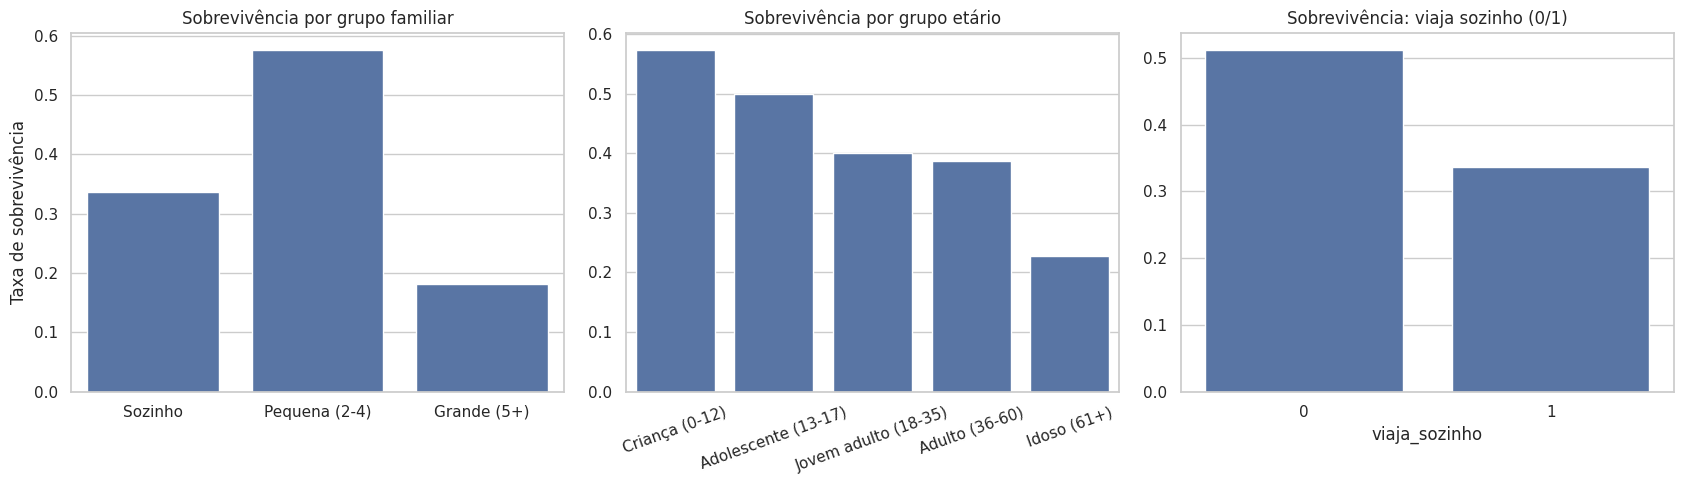

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(data=fe, x='grupo_familia', y='survived', errorbar=None, ax=axes[0])
axes[0].set_title('Sobrevivência por grupo familiar')
axes[0].set_xlabel('')
axes[0].set_ylabel('Taxa de sobrevivência')

sns.barplot(data=fe, x='grupo_etario', y='survived', errorbar=None, ax=axes[1])
axes[1].set_title('Sobrevivência por grupo etário')
axes[1].set_xlabel('')
axes[1].set_ylabel('')
axes[1].tick_params(axis='x', rotation=20)

sns.barplot(data=fe, x='viaja_sozinho', y='survived', errorbar=None, ax=axes[2])
axes[2].set_title('Sobrevivência: viaja sozinho (0/1)')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

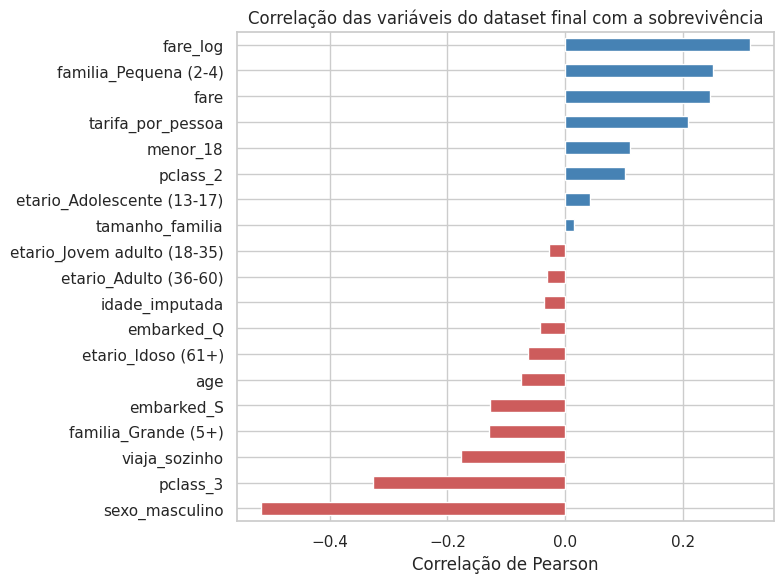

In [25]:
corr_alvo = df_modelo.corr()['survived'].drop('survived').sort_values()

plt.figure(figsize=(8, 6))
corr_alvo.plot(kind='barh', color=np.where(corr_alvo < 0, 'indianred', 'steelblue'))
plt.title('Correlação das variáveis do dataset final com a sobrevivência')
plt.xlabel('Correlação de Pearson')
plt.tight_layout()
plt.show()

### 3.5 Resumo das features criadas

| Feature | Tipo | Descrição |
|---|---|---|
| `idade_imputada` | binária | 1 se a idade foi estimada na limpeza |
| `tamanho_familia` | numérica | `sibsp` + `parch` + 1 |
| `viaja_sozinho` | binária | 1 se `tamanho_familia` = 1 |
| `grupo_familia` | categórica -> one-hot | Sozinho / Pequena (2-4) / Grande (5+) |
| `tarifa_por_pessoa` | numérica | `fare` / `tamanho_familia` |
| `fare_log` | numérica | log(1 + `fare`) |
| `grupo_etario` | categórica -> one-hot | 5 faixas de ciclo de vida |
| `menor_18` | binária | 1 se idade < 18 |
| `sexo_masculino` | binária | codificação de `sex` |
| `embarked_*`, `pclass_*` | one-hot | categorias com `drop_first=True` |
